# 01 — EDA: raw notes for one sample claim

Picks one `CLM_NUM` that has **10-20 notes** and **both** an attorney and litigation involved,
then prints every one of its notes as raw text, separated by a `'='*60` line.


In [1]:
import pandas as pd
import glob
import os

pd.set_option('display.max_colwidth', None)

TARGET_DIR = './TargetData'
NOTES_DIR  = '../BI_Notes'


## Find claims that have BOTH an attorney and litigation


In [2]:
sample = pd.read_parquet(os.path.join(TARGET_DIR, 'BI-Coverage-ALL-2015_2022.parquet'))
att    = pd.read_parquet(os.path.join(TARGET_DIR, 'Endpoint-Attorney-2015_2022.parquet'))
lit    = pd.read_parquet(os.path.join(TARGET_DIR, 'Endpoint-Litigation-2015_2022.parquet'))

cov = sample[['CLM_NUM', 'CLM_CVG_PK']].merge(att[['CLM_CVG_PK', 'ATTNY_FLG']], on='CLM_CVG_PK', how='left')
cov = cov.merge(lit[['CLM_CVG_PK', 'LITIG_FLG']], on='CLM_CVG_PK', how='left')

claim_flags = cov.groupby('CLM_NUM')[['ATTNY_FLG', 'LITIG_FLG']].max()
both_claims = claim_flags[(claim_flags.ATTNY_FLG == 1) & (claim_flags.LITIG_FLG == 1)].index
print(f'{len(both_claims):,} claims have both an attorney and litigation')

11,574 claims have both an attorney and litigation


## Count notes per claim across all BI_Notes batches


In [3]:
note_files = sorted(glob.glob(os.path.join(NOTES_DIR, 'batch_*.csv')))
print(f'{len(note_files)} note batch files found')

counts = pd.Series(dtype='int64')
for f in note_files:
    c = pd.read_csv(f, usecols=['CLAIM_NUM'], dtype={'CLAIM_NUM': str})['CLAIM_NUM'].value_counts()
    counts = counts.add(c, fill_value=0)

counts = counts.astype(int)

16 note batch files found


## Pick one claim: 10-20 notes AND both attorney + litigation


In [4]:
candidates = counts[(counts >= 10) & (counts <= 20)]
candidates = candidates[candidates.index.isin(both_claims)]
print(f'{len(candidates):,} candidate claims match (10-20 notes, attorney AND litigation)')

SAMPLE_CLAIM = '258601594886'
assert SAMPLE_CLAIM in candidates.index, f'{SAMPLE_CLAIM} no longer in the candidate set'
print('Using CLAIM_NUM =', SAMPLE_CLAIM, '| note count =', int(candidates.loc[SAMPLE_CLAIM]))

189 candidate claims match (10-20 notes, attorney AND litigation)
Using CLAIM_NUM = 258601594886 | note count = 19


In [5]:
cov_pks = sample.loc[sample.CLM_NUM == SAMPLE_CLAIM, 'CLM_CVG_PK']

ATTY_MIN_DT  = att.loc[att.CLM_CVG_PK.isin(cov_pks) & (att.ATTNY_FLG == 1), 'ATTNY_DT'].min()
LITIG_MIN_DT = lit.loc[lit.CLM_CVG_PK.isin(cov_pks) & (lit.LITIG_FLG == 1), 'LITIG_DT'].min()

print('Attorney date   (min across this claim\'s coverages):', ATTY_MIN_DT)
print('Litigation date (min across this claim\'s coverages):', LITIG_MIN_DT)

Attorney date   (min across this claim's coverages): 2018-08-28 00:00:00
Litigation date (min across this claim's coverages): 2018-08-27 00:00:00


## Pull and print all of that claim's notes, raw text


In [6]:
import re
import html


def clean_note(text):
    if pd.isna(text):
        return ''
    text = re.sub(r'<br\s*/?>', '\n', text, flags=re.IGNORECASE)
    text = re.sub(r'<[^>]+>', '', text)
    text = html.unescape(text)
    return text

In [7]:
rows = []
for f in note_files:
    df = pd.read_csv(f, usecols=['CLAIM_NUM', 'DATE', 'TEXT_NOTE'], dtype={'CLAIM_NUM': str})
    rows.append(df[df.CLAIM_NUM == SAMPLE_CLAIM])

notes = pd.concat(rows, ignore_index=True)
notes['DATE'] = pd.to_datetime(notes['DATE'], errors='coerce')
notes = notes.sort_values('DATE').reset_index(drop=True)

first_atty_idx  = notes.index[notes.DATE >= ATTY_MIN_DT].min()  if pd.notna(ATTY_MIN_DT)  else None
first_litig_idx = notes.index[notes.DATE >= LITIG_MIN_DT].min() if pd.notna(LITIG_MIN_DT) else None

print(f'CLAIM_NUM {SAMPLE_CLAIM}  -  {len(notes)} notes\n')
for i, row in notes.iterrows():
    label = ''
    if first_atty_idx is not None and i == first_atty_idx:
        label += '  [FIRST NOTE ON/AFTER ATTORNEY DATE]'
    if first_litig_idx is not None and i == first_litig_idx:
        label += '  [FIRST NOTE ON/AFTER LITIGATION DATE]'

    print('=' * 60)
    print(f'NOTE {i + 1}  |  DATE: {row.DATE}{label}')
    print('=' * 60)
    print()
    print(clean_note(row.TEXT_NOTE))
    print()

CLAIM_NUM 258601594886  -  19 notes

NOTE 1  |  DATE: 2018-08-27 00:00:00  [FIRST NOTE ON/AFTER LITIGATION DATE]

A First Report was taken by Agent A1
Email: [EMAIL REDACTED]

Caller - PERSON A
Home Phone: [PHONE REDACTED]
Personal Email: [EMAIL REDACTED]

The Customer expressed the following Concerns:

INS BACKED OUT OF DRIVE AND HIT PED WHO WAS BLOCKED FROM VIEW BY HEDGES; PED GOT UP AND SAID EVERYTHING OK. A YR LATER INS GETTING SUMMONS FROM LAWER ABOUT PED INJURY. 

Vehicle | 2016 - LEXS - ES 350 | [VIN REDACTED]

Attorney - LAWYER 1

Physical Address
[ADDRESS REDACTED]

Business Phone: [PHONE REDACTED]

Police Department - TEANECK PD

Fire Department - 

Vehicle | 2016 - LEXS - ES 350 | [VIN REDACTED]

Is the insured vehicle used as part of a ride-sharing service, like Uber or a taxi service? No

Injured Passenger List
No injured passengers were reported for insured vehicle.

Additional Passenger Information
Were there passengers in the vehicle that were not injured? No

The Negli

### Walkthrough — sample 1 (CLAIM_NUM 258601594886)

**Background:** insured (Person A) was backing out of his driveway in a 2016 Lexus, hedges blocked
his view, and he hit a pedestrian (Person B). She got up and seemed fine at the scene, so nothing was
reported for about a year.

- **Note 1 (2018-08-27)** — First Report / FNOL, filed late (~1 year after the actual accident date
  6/1/2017). Insured only reported it because he just got served with a lawsuit summons out of nowhere —
  he'd assumed everything was fine since the pedestrian walked away. No property damage, no witnesses
  flagged as a concern. First note on/after the litigation date — the suit was already filed before the
  claim was even opened in the system.
- **Note 2 (2018-08-28)** — Summons & Complaint formally received, filed by attorney Lawyer 1 on
  behalf of Person B (Docket: Bergen Cty [DOCKET REDACTED], *Person B v. Person A*). Adjuster reviews coverage
  (\$250K/\$500K BI, \$250K PIP), notes liability is 90-100% on the insured (hedges blocked view), and sets
  an initial reserve of **\$10,000**. First note on/after the attorney date.
- **Note 3 (2018-10-18)** — Routine file follow-up: suit is active, defense counsel handling it, no
  medical records received yet. Reserve held at \$10K pending injury info.
- **Note 4 (2018-11-28)** — Administrative "BULK TRANSFER" (file reassigned/moved systems) — no
  substantive update.
- **Note 5 (2018-12-04)** — Fuller case summary written up: confirms facts, liability (90-100% insured),
  identifies the plaintiff (Person B, 65F) with "soft tissue injuries," reserve still \$10K. Action plan:
  get medical records ("Roggs" = responses to interrogatories/discovery demands).
- **Note 6 (2018-12-20)** — Status update sent to the insured's agency contact: discovery and medical
  records still pending.
- **Note 7 (2019-02-11)** — Chasing defense counsel (Lawyer 3) for status on the plaintiff's discovery
  responses — still not received.
- **Note 8 (2019-02-12)** — Defense counsel grants the plaintiff a 14-day extension to respond to
  discovery.
- **Note 9 (2019-02-15)** — Note that the case won't be ready for the March settlement conference.
- **Note 10 (2019-03-01)** — Discovery responses ("Roggs") finally received; adjuster will review.
- **Note 11 (2019-03-05)** — Insured's agent asks for a status update; told discovery was just received
  and under review.
- **Note 12 (2019-03-06)** — Reviewed discovery: plaintiff is 65F, ER-only treatment, and in her own
  responses she states she has **no permanent injury**. This is a big deal — a low-damages case.
  Adjuster asks defense counsel whether to push for summary judgment on the "verbal threshold" (NJ's
  injury-severity bar for BI suits).
- **Note 13 (2019-03-11)** — Defense counsel says they'd need plaintiff depositions before summary
  judgment is viable — but the plaintiff's attorney has reached out wanting to settle instead and will
  send a demand. Defense counsel reads this as the plaintiff's side recognizing the case isn't worth much.
- **Note 14 (2019-03-12)** — Adjuster leaves a voicemail for plaintiff's attorney Lawyer 1 to start
  settlement talks directly.
- **Note 15 (2019-03-13)** — Settlement negotiated directly over the phone (plaintiff's attorney had the
  plaintiff on the call too — who, notably, is also an Insurance Company 1 policyholder). Opened at \$1,500,
  settled at **\$2,500**, to avoid the cost of depositions/IME on a thin-injury case.
- **Note 16 (2019-03-14)** — Insured's agent told the suit has been settled.
- **Note 17 (2019-04-08)** — Closing papers (settlement/release documents) received from defense counsel.
- **Note 18 (2019-04-10)** — Chasing the plaintiff attorney's W-9 (needed to cut the settlement check);
  received and routed to issue payment.
- **Note 19 (2019-04-11)** — **Claim closed.** \$2,500 BI payment issued (check to attorney Lawyer 1
  + Person B), claim marked for closure once payment clears.

**Overall arc:** a very low-severity pedestrian-strike claim that only became a BI matter because of a
year-late lawsuit, got assigned an attorney and defended, then resolved cheaply (\$2,500) once discovery
showed minimal injury — settled directly between the adjuster and plaintiff's counsel rather than going
further into litigation (no depositions, no IME, no SJM motion actually filed).

## Second example claim — attorney AND litigation = 1, with notes BOTH before and on/after both dates

In [8]:
all_claims = candidates.index

rows = []
for f in note_files:
    df = pd.read_csv(f, usecols=['CLAIM_NUM', 'DATE', 'TEXT_NOTE'], dtype={'CLAIM_NUM': str})
    rows.append(df[df.CLAIM_NUM.isin(all_claims)])

all_notes = pd.concat(rows, ignore_index=True)
all_notes['DATE'] = pd.to_datetime(all_notes['DATE'], errors='coerce')

cov = sample[['CLM_NUM', 'CLM_CVG_PK']]
atty_dates  = cov.merge(att[att.ATTNY_FLG == 1][['CLM_CVG_PK', 'ATTNY_DT']], on='CLM_CVG_PK').groupby('CLM_NUM')['ATTNY_DT'].min()
litig_dates = cov.merge(lit[lit.LITIG_FLG == 1][['CLM_CVG_PK', 'LITIG_DT']], on='CLM_CVG_PK').groupby('CLM_NUM')['LITIG_DT'].min()

SAMPLE_CLAIM_2 = 'A83602061136'
assert SAMPLE_CLAIM_2 in candidates.index, f'{SAMPLE_CLAIM_2} no longer in the candidate set'

ATTY_MIN_DT_2  = atty_dates[SAMPLE_CLAIM_2]
LITIG_MIN_DT_2 = litig_dates[SAMPLE_CLAIM_2]
print('Using CLAIM_NUM =', SAMPLE_CLAIM_2, '| note count =', int(candidates.loc[SAMPLE_CLAIM_2]))
print('Attorney date   (min across this claim\'s coverages):', ATTY_MIN_DT_2)
print('Litigation date (min across this claim\'s coverages):', LITIG_MIN_DT_2)

notes2 = all_notes.loc[all_notes.CLAIM_NUM == SAMPLE_CLAIM_2].sort_values('DATE').reset_index(drop=True)

first_atty_idx_2  = notes2.index[notes2.DATE >= ATTY_MIN_DT_2].min()  if pd.notna(ATTY_MIN_DT_2)  else None
first_litig_idx_2 = notes2.index[notes2.DATE >= LITIG_MIN_DT_2].min() if pd.notna(LITIG_MIN_DT_2) else None

print(f'\nCLAIM_NUM {SAMPLE_CLAIM_2}  -  {len(notes2)} notes\n')
for i, row in notes2.iterrows():
    label = ''
    if first_atty_idx_2 is not None and i == first_atty_idx_2:
        label += '  [FIRST NOTE ON/AFTER ATTORNEY DATE]'
    if first_litig_idx_2 is not None and i == first_litig_idx_2:
        label += '  [FIRST NOTE ON/AFTER LITIGATION DATE]'

    print('=' * 60)
    print(f'NOTE {i + 1}  |  DATE: {row.DATE}{label}')
    print('=' * 60)
    print()
    print(clean_note(row.TEXT_NOTE))
    print()

Using CLAIM_NUM = A83602061136 | note count = 14
Attorney date   (min across this claim's coverages): 2022-03-02 00:00:00
Litigation date (min across this claim's coverages): 2022-03-14 00:00:00

CLAIM_NUM A83602061136  -  14 notes

NOTE 1  |  DATE: 2022-01-31 00:00:00

A First Report was taken by Agent B1
Email: agent1@[EMAIL DOMAIN REDACTED]

Caller - Person C
Cellular Phone: [PHONE REDACTED]
Personal Email: [EMAIL REDACTED]

The Customer expressed the following Concerns:

OV info in police report. 

Third Party Vehicle | UNK - UNK - UNK | UNK

Other Carrier Name: UNK
Policy Number or Claim Number: UNK

Police Department - White plains PD

Case Number - 22-06043

Vehicle | 2009 - HYUNDAI - ELANTRA GLS/SE | [VIN REDACTED]

Is the insured vehicle used as part of a ride-sharing service, like Uber or a taxi service? No

Injured Passenger List
No injured passengers were reported for insured vehicle.

Additional Passenger Information
Were there passengers in the vehicle that were not injur

### Walkthrough — sample 2 (CLAIM_NUM A83602061136)

**Background:** insured (Person C) was driving her 2009 Hyundai Elantra on North Broadway
in White Plains when another vehicle (OV) merged into her lane and the two collided. At first it looked
like a routine, no-injury property-damage claim with the insured mostly at fault.

- **Note 1 (2022-01-31)** — FNOL. Insured reports a merging accident, no injuries, no tow, police report
  taken. She has no collision coverage, so no vehicle inspection/repair payment is owed on her own car —
  at this point there's no BI exposure identified at all. This note is *before* either target date.
- **Note 2 (2022-03-02)** — A law firm (Law Firm 1) sends a letter of representation for
  Person D, a passenger in the other vehicle who was injured. This is what actually opens the BI claim.
  First note on/after the attorney date.
- **Note 3 (2022-03-03)** — Adjuster logs BI exposure: 100/300 limits, liability initially assessed as
  "majority vs. insured," injured party (Person D) is attorney-represented, and the other vehicle turns out
  to carry its own no-fault coverage through Insurance Company 2.
- **Note 4 (2022-03-08)** — Insured confirms she was served with a Summons & Complaint (lawsuit) by mail.
  Reviewing the police report and her account more closely, the adjuster now reassesses liability down to
  only ~25% against the insured (the other car didn't have the right of way).
- **Note 5 (2022-03-14)** — Case formally sent to defense counsel with instructions to answer the lawsuit
  on the insured's behalf. First note on/after the litigation date.
- **Note 6 (2022-04-25)** — Defense counsel (Lawyer 6) files an answer. Claimant's attorney reports she
  just had right shoulder surgery, with ongoing neck/back/shoulder treatment. Adjuster also discovers the
  other vehicle is commercially insured by Insurance Company 2, who has already paid ~\$5,017 in no-fault
  medical benefits.
- **Note 7 (2022-05-10)** — Insurance Company 2 (the other insurer) agrees to accept full liability for the
  accident — this drops the insured's own liability share to **0%** for the BI claim, even though the
  lawsuit is still proceeding.
- **Note 8 (2022-05-11)** — Procedural update from defense counsel: a co-defendant is trying to move the
  case's venue from Bronx to Westchester.
- **Note 9 (2022-05-12)** — File review confirms 0% liability for the insured; co-defendant Insurance Company 2
  has accepted 100%. Claimant alleges shoulder surgery. Reserve raised sharply to **\$50,000** given the
  surgery claim, even though the insured's own fault share is zero.
- **Note 10 (2022-06-21)** — Bill of particulars received, detailing neck/back/shoulder injury claims;
  shoulder already factored into the reserve due to the surgery.
- **Note 11 (2022-07-07)** — Defense counsel confirms medical records received; now waiting on deposition
  (EBT) dates.
- **Note 12 (2022-07-14)** — Settlement negotiation: adjuster offers \$2,500 (based on a 10% liability
  share despite the 0% assessment, to avoid litigation costs), claimant's attorney wants \$10,000, they
  settle in the middle at **\$7,500**.
- **Note 13 (2022-07-18)** — Release documents emailed to the attorney.
- **Note 14 (2022-07-22)** — **Case fully resolved.** Stipulation signed by plaintiff and co-defendants,
  \$7,500 payment issued, file closed.

**Overall arc:** a merging-accident claim where the insured initially looked majority-at-fault, but as
facts developed the co-defendant's commercial insurer (Insurance Company 2) accepted full liability — dropping
the insured's own fault share to 0%. Despite that, the claim still carried real BI exposure because of a
represented passenger's shoulder surgery, and was ultimately resolved with a modest **nuisance-value
contribution (\$7,500)** to avoid litigation costs, rather than fighting it out to a liability verdict.

---
## Corpus-wide descriptive EDA (all 16 `BI_Notes` batches)

Everything below scans the **full** `BI_Notes` corpus once (not just the 2 example claims above) to
characterize the data: note length, notes-per-claim, how long claims stay "active" in terms of
note-taking, note volume over time, and the vocabulary itself (top words + word cloud).

In [9]:
import time
import numpy as np
import matplotlib.pyplot as plt

QUANTILES = [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]

t0 = time.time()
meta_parts = []
for f in note_files:
    df = pd.read_csv(f, usecols=['CLAIM_NUM', 'DATE', 'TEXT_NOTE'], dtype={'CLAIM_NUM': str})
    cleaned = df['TEXT_NOTE'].fillna('')
    cleaned = cleaned.str.replace(r'<br\s*/?>', ' ', regex=True)
    cleaned = cleaned.str.replace(r'<[^>]+>', '', regex=True)

    meta_parts.append(pd.DataFrame({
        'CLAIM_NUM': df['CLAIM_NUM'],
        'DATE': pd.to_datetime(df['DATE'], errors='coerce'),
        'N_WORDS': cleaned.str.split().map(len),
        'N_CHARS': cleaned.str.len(),
    }))

notes_meta = pd.concat(meta_parts, ignore_index=True)
print(f'Scanned {len(note_files)} batch files in {time.time() - t0:.1f}s')
print(f'Total notes: {len(notes_meta):,}')
print(f'Total distinct claims: {notes_meta.CLAIM_NUM.nunique():,}')
notes_meta.head()

Scanned 16 batch files in 142.6s
Total notes: 4,645,819
Total distinct claims: 138,233


,CLAIM_NUM,DATE,N_WORDS,N_CHARS
0,020001368300,2015-01-29,666,4260
1,020001368300,2015-02-13,307,1642
2,020001368300,2015-02-18,43,242
3,020001368300,2015-02-19,105,831
4,020001368300,2015-02-20,66,353


### Words per note — distribution

Words per note - describe():
count    4.645819e+06
mean     1.049563e+02
std      2.774188e+02
min      0.000000e+00
25%      2.000000e+01
50%      4.600000e+01
75%      1.160000e+02
max      9.863400e+04
Name: N_WORDS, dtype: float64

Words per note - quantiles:


0.00        0.0
0.01        3.0
0.05        6.0
0.10       10.0
0.25       20.0
0.50       46.0
0.75      116.0
0.90      249.0
0.95      381.0
0.99      789.0
1.00    98634.0
Name: N_WORDS, dtype: float64


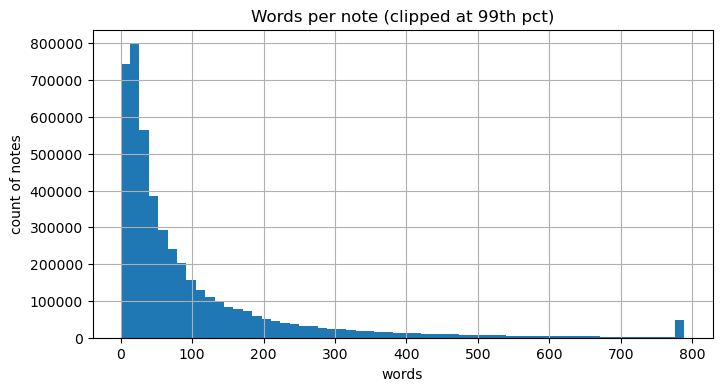

In [10]:
print('Words per note - describe():')
print(notes_meta.N_WORDS.describe())
print('\nWords per note - quantiles:')
print(notes_meta.N_WORDS.quantile(QUANTILES))

notes_meta.N_WORDS.clip(upper=notes_meta.N_WORDS.quantile(0.99)).hist(bins=60, figsize=(8, 4))
plt.title('Words per note (clipped at 99th pct)')
plt.xlabel('words')
plt.ylabel('count of notes')
plt.show()

### Characters per note — distribution

Characters per note - describe():
count    4.645819e+06
mean     6.351182e+02
std      1.721673e+03
min      0.000000e+00
25%      1.180000e+02
50%      2.760000e+02
75%      6.990000e+02
max      6.074560e+05
Name: N_CHARS, dtype: float64

Characters per note - quantiles:


0.00         0.0
0.01        17.0
0.05        36.0
0.10        57.0
0.25       118.0
0.50       276.0
0.75       699.0
0.90      1509.0
0.95      2320.0
0.99      4775.0
1.00    607456.0
Name: N_CHARS, dtype: float64


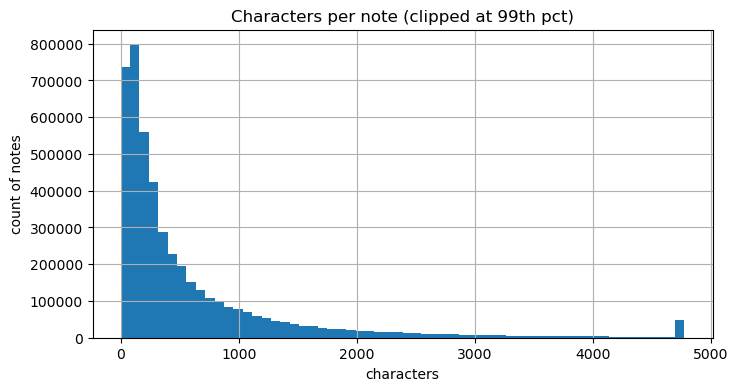

In [11]:
print('Characters per note - describe():')
print(notes_meta.N_CHARS.describe())
print('\nCharacters per note - quantiles:')
print(notes_meta.N_CHARS.quantile(QUANTILES))

notes_meta.N_CHARS.clip(upper=notes_meta.N_CHARS.quantile(0.99)).hist(bins=60, figsize=(8, 4))
plt.title('Characters per note (clipped at 99th pct)')
plt.xlabel('characters')
plt.ylabel('count of notes')
plt.show()

### Notes per claim — distribution

Notes per claim - describe():
count    138233.000000
mean         33.608610
std          28.967038
min           1.000000
25%          15.000000
50%          26.000000
75%          43.000000
max         443.000000
dtype: float64

Notes per claim - quantiles:
0.00      1.0
0.01      1.0
0.05      3.0
0.10      7.0
0.25     15.0
0.50     26.0
0.75     43.0
0.90     69.0
0.95     90.0
0.99    141.0
1.00    443.0
dtype: float64


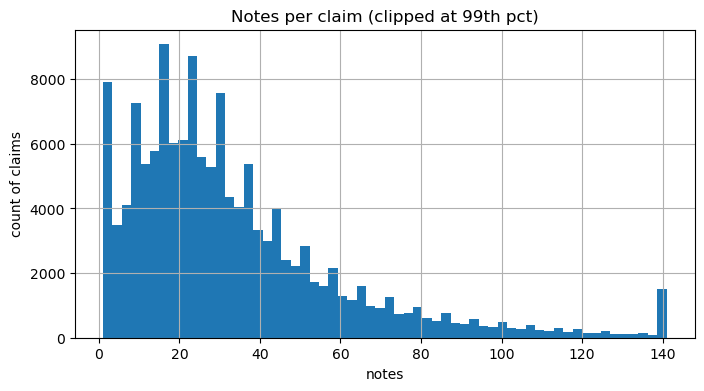

In [12]:
notes_per_claim = notes_meta.groupby('CLAIM_NUM').size()

print('Notes per claim - describe():')
print(notes_per_claim.describe())
print('\nNotes per claim - quantiles:')
print(notes_per_claim.quantile(QUANTILES))

notes_per_claim.clip(upper=notes_per_claim.quantile(0.99)).hist(bins=60, figsize=(8, 4))
plt.title('Notes per claim (clipped at 99th pct)')
plt.xlabel('notes')
plt.ylabel('count of claims')
plt.show()

### Claim duration — days from first to last note per claim

Claim note-taking span in days (first note -> last note) - describe():
count    138233.000000
mean        522.062257
std         486.852518
min           0.000000
25%         159.000000
50%         374.000000
75%         751.000000
max        4041.000000
Name: DATE, dtype: float64

span (days) - quantiles:
0.00       0.0
0.01       0.0
0.05      11.0
0.10      53.0
0.25     159.0
0.50     374.0
0.75     751.0
0.90    1192.0
0.95    1482.0
0.99    2155.0
1.00    4041.0
Name: DATE, dtype: float64


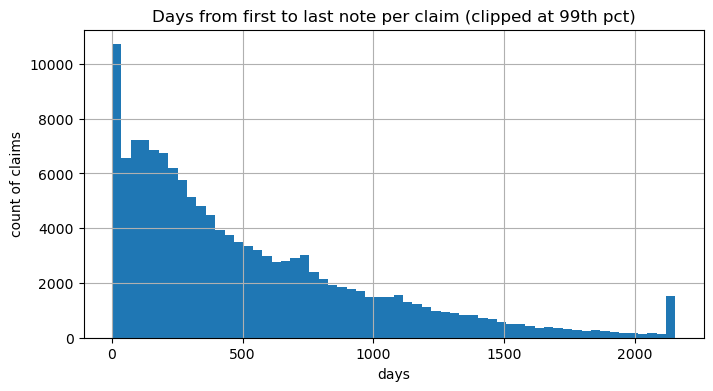

In [13]:
claim_span_days = (
    notes_meta.dropna(subset=['DATE'])
    .groupby('CLAIM_NUM')['DATE']
    .agg(lambda s: (s.max() - s.min()).days)
)

print('Claim note-taking span in days (first note -> last note) - describe():')
print(claim_span_days.describe())
print('\nspan (days) - quantiles:')
print(claim_span_days.quantile(QUANTILES))

claim_span_days.clip(upper=claim_span_days.quantile(0.99)).hist(bins=60, figsize=(8, 4))
plt.title('Days from first to last note per claim (clipped at 99th pct)')
plt.xlabel('days')
plt.ylabel('count of claims')
plt.show()

### Gap between consecutive notes within a claim

Gap between consecutive notes in days - describe():
count    4.507586e+06
mean     1.600995e+01
std      5.187658e+01
min      1.000000e+00
25%      2.000000e+00
50%      5.000000e+00
75%      1.500000e+01
max      3.738000e+03
Name: DATE, dtype: float64

gap (days) - quantiles:


0.00       1.0
0.01       1.0
0.05       1.0
0.10       1.0
0.25       2.0
0.50       5.0
0.75      15.0
0.90      35.0
0.95      57.0
0.99     147.0
1.00    3738.0
Name: DATE, dtype: float64


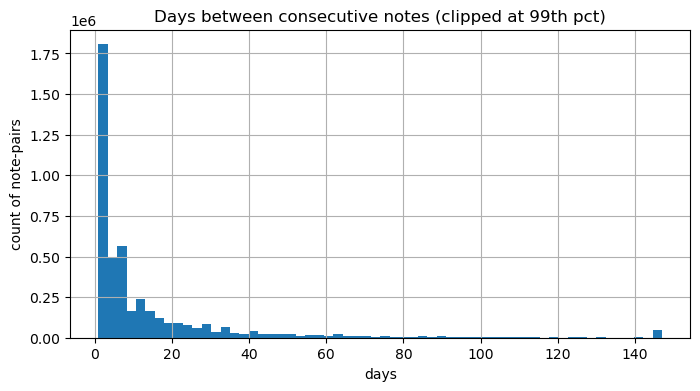

In [14]:
notes_sorted = notes_meta.dropna(subset=['DATE']).sort_values(['CLAIM_NUM', 'DATE'])
gap_days = notes_sorted.groupby('CLAIM_NUM')['DATE'].diff().dt.days.dropna()

print('Gap between consecutive notes in days - describe():')
print(gap_days.describe())
print('\ngap (days) - quantiles:')
print(gap_days.quantile(QUANTILES))

gap_days.clip(upper=gap_days.quantile(0.99)).hist(bins=60, figsize=(8, 4))
plt.title('Days between consecutive notes (clipped at 99th pct)')
plt.xlabel('days')
plt.ylabel('count of note-pairs')
plt.show()

### Days since the claim's FIRST note — per-note distribution (note #n happens on day...?)

Days since claim's first note, per note - describe():
count    4.645819e+06
mean     2.956535e+02
std      3.757452e+02
min      0.000000e+00
25%      2.900000e+01
50%      1.320000e+02
75%      4.370000e+02
max      4.041000e+03
Name: DAYS_SINCE_FIRST, dtype: float64

days since first note - quantiles:
0.00       0.0
0.01       0.0
0.05       2.0
0.10       6.0
0.25      29.0
0.50     132.0
0.75     437.0
0.90     839.0
0.95    1085.0
0.99    1582.0
1.00    4041.0
Name: DAYS_SINCE_FIRST, dtype: float64


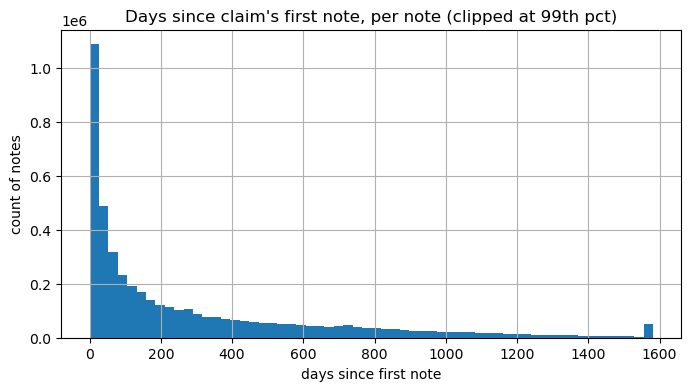

In [15]:
notes_sorted2 = notes_meta.dropna(subset=['DATE']).sort_values(['CLAIM_NUM', 'DATE']).copy()
first_date = notes_sorted2.groupby('CLAIM_NUM')['DATE'].transform('min')
notes_sorted2['DAYS_SINCE_FIRST'] = (notes_sorted2['DATE'] - first_date).dt.days
notes_sorted2['NOTE_INDEX'] = notes_sorted2.groupby('CLAIM_NUM').cumcount() + 1

print('Days since claim\'s first note, per note - describe():')
print(notes_sorted2.DAYS_SINCE_FIRST.describe())
print('\ndays since first note - quantiles:')
print(notes_sorted2.DAYS_SINCE_FIRST.quantile(QUANTILES))

notes_sorted2.DAYS_SINCE_FIRST.clip(upper=notes_sorted2.DAYS_SINCE_FIRST.quantile(0.99)).hist(bins=60, figsize=(8, 4))
plt.title('Days since claim\'s first note, per note (clipped at 99th pct)')
plt.xlabel('days since first note')
plt.ylabel('count of notes')
plt.show()

### Same distribution, clipped to the first year (365 days) — less right-skew

3,302,541 / 4,645,819 notes (71.1%) fall within the first 365 days

Days since first note, clipped to <= 365 - describe():
count    3.302541e+06
mean     9.769572e+01
std      9.993579e+01
min      0.000000e+00
25%      1.700000e+01
50%      5.800000e+01
75%      1.570000e+02
max      3.650000e+02
Name: DAYS_SINCE_FIRST, dtype: float64


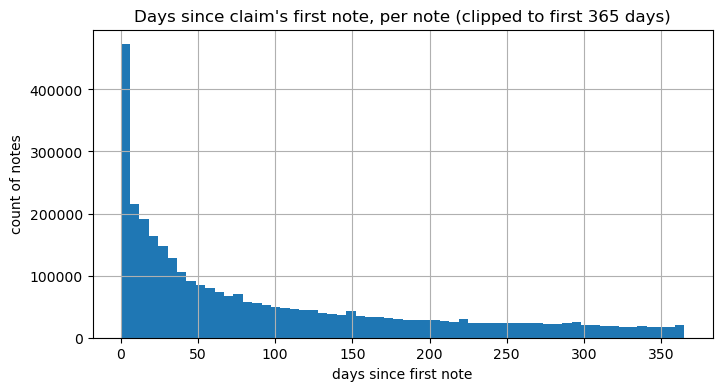

In [16]:
within_year = notes_sorted2.loc[notes_sorted2.DAYS_SINCE_FIRST <= 365, 'DAYS_SINCE_FIRST']
pct_within_year = len(within_year) / len(notes_sorted2)

print(f'{len(within_year):,} / {len(notes_sorted2):,} notes ({pct_within_year:.1%}) fall within the first 365 days')
print('\nDays since first note, clipped to <= 365 - describe():')
print(within_year.describe())

within_year.hist(bins=60, figsize=(8, 4))
plt.title('Days since claim\'s first note, per note (clipped to first 365 days)')
plt.xlabel('days since first note')
plt.ylabel('count of notes')
plt.show()

### Median day-of-occurrence by note sequence number (note #1, #2, #3... — first 20 notes)

Median days-since-first-note, by note sequence number:
NOTE_INDEX
1       0.0
2       1.0
3       4.0
4       6.0
5       9.0
6      13.0
7      17.0
8      22.0
9      27.0
10     31.0
11     36.0
12     42.0
13     49.0
14     57.0
15     64.0
16     73.0
17     82.0
18     92.0
19    102.0
20    113.0
Name: DAYS_SINCE_FIRST, dtype: float64


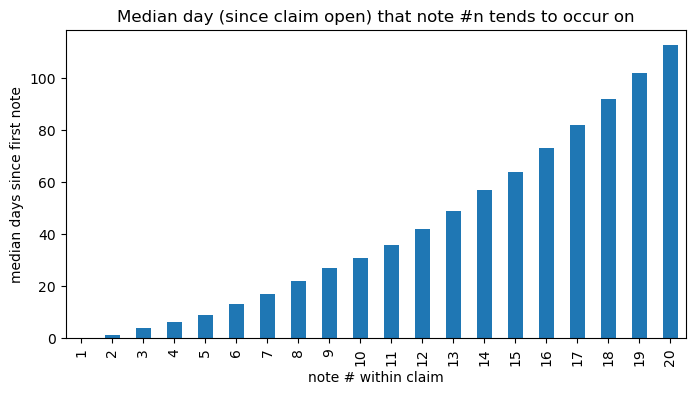

In [17]:
by_index = (
    notes_sorted2[notes_sorted2.NOTE_INDEX <= 20]
    .groupby('NOTE_INDEX')['DAYS_SINCE_FIRST']
    .median()
)

print('Median days-since-first-note, by note sequence number:')
print(by_index)

by_index.plot(kind='bar', figsize=(8, 4))
plt.title('Median day (since claim open) that note #n tends to occur on')
plt.xlabel('note # within claim')
plt.ylabel('median days since first note')
plt.show()

### Notes volume over calendar time

Notes per year:
DATE
2015    141938
2016    244734
2017    296348
2018    331616
2019    483235
2020    467647
2021    479128
2022    486319
2023    495439
2024    528105
2025    524924
2026    166386
Name: count, dtype: int64


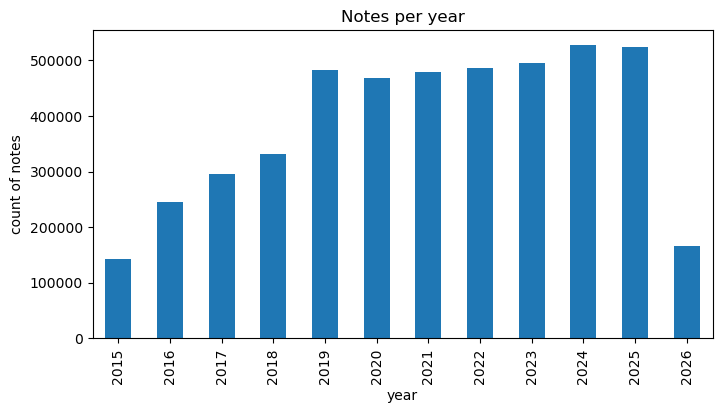

In [18]:
notes_by_year = notes_meta.dropna(subset=['DATE'])['DATE'].dt.year.value_counts().sort_index()
print('Notes per year:')
print(notes_by_year)

notes_by_year.plot(kind='bar', figsize=(8, 4))
plt.title('Notes per year')
plt.xlabel('year')
plt.ylabel('count of notes')
plt.show()

### Vocabulary — most common words (random sample across all batches, for speed)

Sampled 50,016 notes (of 4,645,819 total) for vocabulary analysis



Top 30 words:
date            37,108
time            32,627
name            29,239
claimant        28,883
will            27,895
loss            25,551
vehicle         24,682
claim           23,949
insured         22,778
pip             22,491
file            20,644
called          20,102
sent            20,072
policy          19,586
insd            19,578
author          19,190
left            16,656
back            16,153
clmt            15,891
rental          14,501
call            14,246
advised         14,020
updated         12,217
received        12,161
email           12,057
atty            12,029
number          11,949
report          11,787
div             11,316
yes             11,166


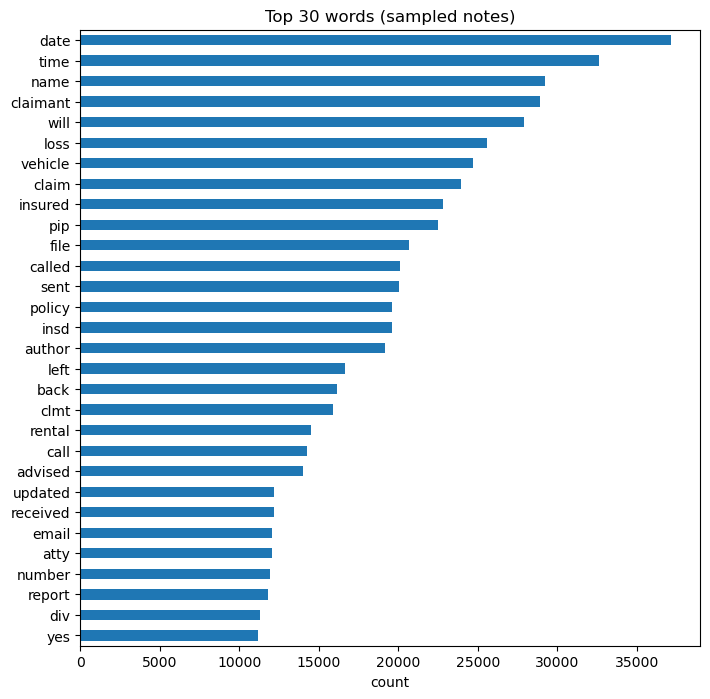

In [19]:
import re
from collections import Counter
from wordcloud import WordCloud, STOPWORDS

SAMPLE_N = 50_000
rng = np.random.default_rng(42)

sample_texts = []
for f in note_files:
    df = pd.read_csv(f, usecols=['TEXT_NOTE'])
    n = min(len(df), SAMPLE_N // len(note_files) + 1)
    idx = rng.choice(len(df), size=n, replace=False)
    sample_texts.extend(df['TEXT_NOTE'].iloc[idx].fillna('').tolist())

print(f'Sampled {len(sample_texts):,} notes (of {len(notes_meta):,} total) for vocabulary analysis')

cleaned_sample = [clean_note(t) for t in sample_texts]
all_text = ' '.join(cleaned_sample).lower()
tokens = re.findall(r"[a-z']+", all_text)

STOP = set(STOPWORDS)
tokens = [t for t in tokens if t not in STOP and len(t) > 2]

word_counts = Counter(tokens)
top30 = word_counts.most_common(30)

print('\nTop 30 words:')
for w, c in top30:
    print(f'{w:15s} {c:,}')

pd.Series(dict(top30)).sort_values().plot(kind='barh', figsize=(8, 8))
plt.title('Top 30 words (sampled notes)')
plt.xlabel('count')
plt.show()

### Word cloud

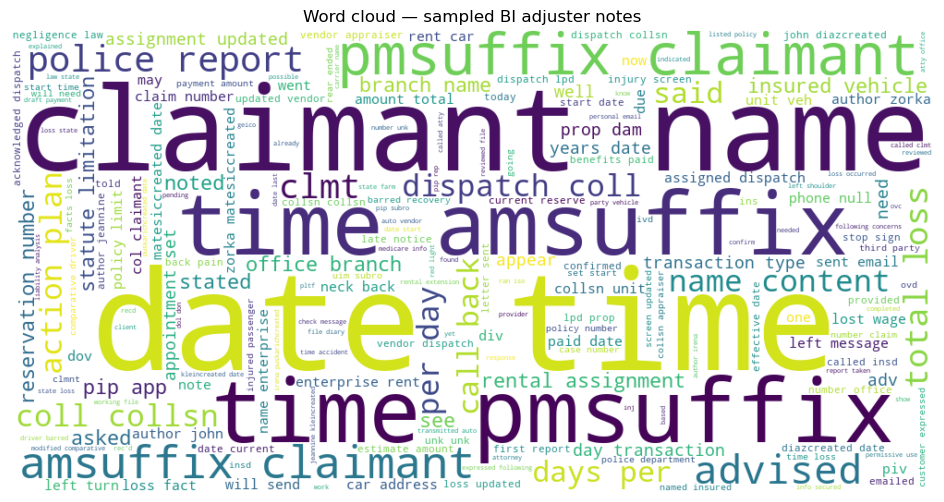

In [20]:
wc = WordCloud(width=1000, height=500, background_color='white', stopwords=STOP).generate(' '.join(tokens))

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud — sampled BI adjuster notes')
plt.show()

---
## Target distributions by year, and by severity bucket

Builds one combined coverage-grain table (`cov_full`) joining `sample` + `att` + `lit` + `sev` on
`CLM_CVG_PK`, then looks at: how the Attorney and Litigation flags trend by claim-open year, how the
severity bucket mix trends by claim-open year, and — since there is **no existing column** that
cross-tabulates Attorney/Litigation rate against severity bucket — a derived table/chart for that too.

In [21]:
sev = pd.read_parquet(os.path.join(TARGET_DIR, 'Endpoint-Severity-2015_2022.parquet'))

cov_full = sample[['CLM_NUM', 'CLM_CVG_PK', 'CLM_OPEN_DT', 'ORG_GROUP_NAME', 'POL_STATE', 'LOSS_STATE']].merge(
    att[['CLM_CVG_PK', 'ATTNY_FLG', 'ATTNY_DT']], on='CLM_CVG_PK', how='left'
)
cov_full = cov_full.merge(lit[['CLM_CVG_PK', 'LITIG_FLG', 'LITIG_DT']], on='CLM_CVG_PK', how='left')
cov_full = cov_full.merge(
    sev[['CLM_CVG_PK', 'SEV_BUCKET', 'OPEN_CLOSE_STATUS_ASOF_02272026', 'LAST_CLOSE_DT']],
    on='CLM_CVG_PK', how='left'
)

cov_full['CLM_OPEN_DT'] = pd.to_datetime(cov_full['CLM_OPEN_DT'], errors='coerce')
cov_full['OPEN_YEAR'] = cov_full['CLM_OPEN_DT'].dt.year

print(f'{len(cov_full):,} coverages')
cov_full.head()

169,322 coverages


,CLM_NUM,CLM_CVG_PK,CLM_OPEN_DT,ORG_GROUP_NAME,POL_STATE,LOSS_STATE,ATTNY_FLG,ATTNY_DT,LITIG_FLG,LITIG_DT,SEV_BUCKET,OPEN_CLOSE_STATUS_ASOF_02272026,LAST_CLOSE_DT,OPEN_YEAR
0,072601415526,65493420,2015-10-28,Direct,NJ,NJ,1,2015-11-10,0,NaT,1,CLOSE,2017-08-17,2015
1,048401391484,68430618,2015-06-15,Direct,NJ,NJ,1,2015-07-28,0,NaT,2,CLOSE,2017-11-15,2015
2,683701419137,66766720,2015-11-18,Independent,NJ,LA,1,2016-05-06,0,NaT,0,CLOSE,2017-10-13,2015
3,251901373119,68430496,2015-02-26,Independent,NJ,NJ,1,2015-03-16,0,NaT,3,CLOSE,2017-12-21,2015
4,672401364024,68106803,2015-01-03,Direct,NJ,NJ,1,2015-02-26,0,NaT,2,CLOSE,2017-12-05,2015


### Attorney rate by claim-open year

           ATTNY_RATE  N_ATTNY  N_COVERAGES
OPEN_YEAR                                  
2015         0.392914     8184        20829
2016         0.399619     9638        24118
2017         0.415035     9518        22933
2018         0.420801     9431        22412
2019         0.423049     9214        21780
2020         0.466294     8266        17727
2021         0.484285     9769        20172
2022         0.509855     9338        18315
2023         0.632388      535          846
2024         0.800000      120          150
2025         0.650000       26           40


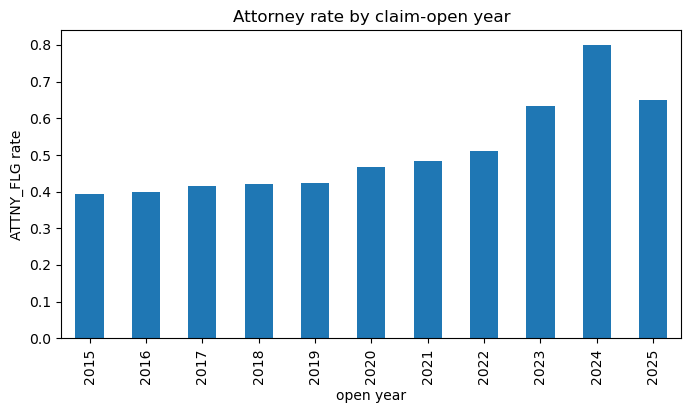

In [22]:
atty_by_year = cov_full.groupby('OPEN_YEAR')['ATTNY_FLG'].agg(['mean', 'sum', 'count'])
atty_by_year.columns = ['ATTNY_RATE', 'N_ATTNY', 'N_COVERAGES']
print(atty_by_year)

atty_by_year['ATTNY_RATE'].plot(kind='bar', figsize=(8, 4))
plt.title('Attorney rate by claim-open year')
plt.xlabel('open year')
plt.ylabel('ATTNY_FLG rate')
plt.show()

### Litigation rate by claim-open year

           LITIG_RATE  N_LITIG  N_COVERAGES
OPEN_YEAR                                  
2015         0.035335      736        20829
2016         0.061033     1472        24118
2017         0.075742     1737        22933
2018         0.088033     1973        22412
2019         0.085904     1871        21780
2020         0.089524     1587        17727
2021         0.079962     1613        20172
2022         0.071690     1313        18315
2023         0.087470       74          846
2024         0.186667       28          150
2025         0.050000        2           40


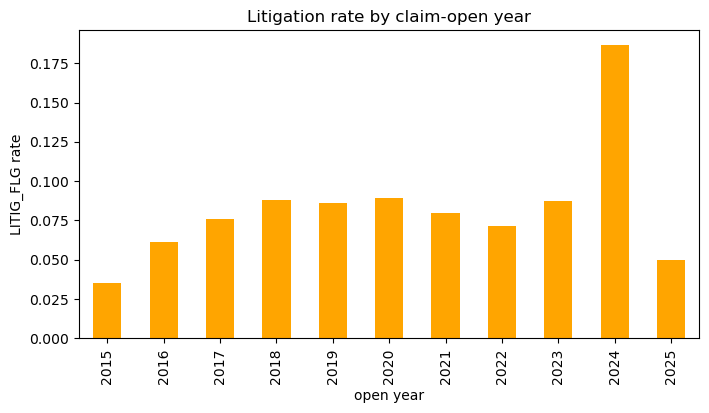

In [23]:
litig_by_year = cov_full.groupby('OPEN_YEAR')['LITIG_FLG'].agg(['mean', 'sum', 'count'])
litig_by_year.columns = ['LITIG_RATE', 'N_LITIG', 'N_COVERAGES']
print(litig_by_year)

litig_by_year['LITIG_RATE'].plot(kind='bar', figsize=(8, 4), color='orange')
plt.title('Litigation rate by claim-open year')
plt.xlabel('open year')
plt.ylabel('LITIG_FLG rate')
plt.show()

### Severity bucket mix by claim-open year

SEV_BUCKET      0      1      2      3      4
OPEN_YEAR                                    
2015        0.581  0.177  0.124  0.084  0.035
2016        0.610  0.167  0.116  0.075  0.032
2017        0.609  0.165  0.120  0.077  0.029
2018        0.603  0.162  0.128  0.078  0.030
2019        0.605  0.166  0.119  0.080  0.031
2020        0.608  0.152  0.124  0.085  0.032
2021        0.620  0.141  0.125  0.084  0.030
2022        0.586  0.148  0.140  0.095  0.031
2023        0.612  0.136  0.147  0.078  0.027
2024        0.753  0.067  0.093  0.067  0.020
2025        0.900  0.025  0.000  0.050  0.025


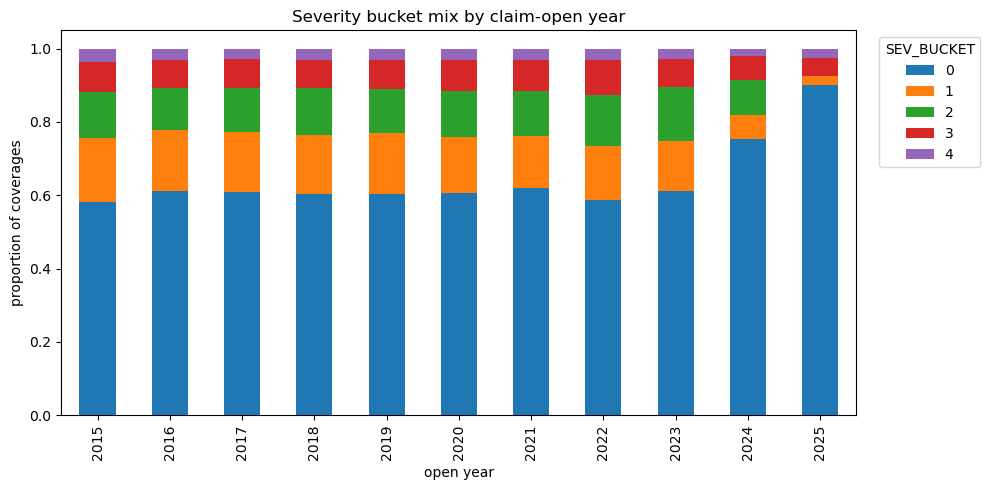

In [24]:
sev_by_year = pd.crosstab(cov_full['OPEN_YEAR'], cov_full['SEV_BUCKET'], normalize='index')
print(sev_by_year.round(3))

sev_by_year.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Severity bucket mix by claim-open year')
plt.xlabel('open year')
plt.ylabel('proportion of coverages')
plt.legend(title='SEV_BUCKET', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Attorney & litigation rate BY severity bucket

There is no pre-existing column that cross-tabulates this — `ATTNY_FLG`, `LITIG_FLG`, and `SEV_BUCKET`
live in three separate endpoint tables, each keyed only by `CLM_CVG_PK`. This builds the cross-tab from
`cov_full` directly.

            ATTNY_FLG  LITIG_FLG  N_COVERAGES
SEV_BUCKET                                   
0            0.254873   0.015146       102141
1            0.379221   0.039749        27095
2            0.935171   0.153839        21009
3            0.949598   0.301687        13809
4            0.943622   0.452544         5268


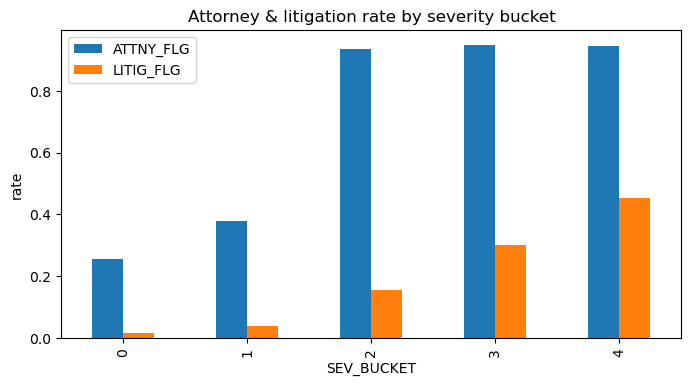

In [25]:
rate_by_bucket = cov_full.groupby('SEV_BUCKET')[['ATTNY_FLG', 'LITIG_FLG']].mean()
rate_by_bucket['N_COVERAGES'] = cov_full.groupby('SEV_BUCKET').size()
print(rate_by_bucket)

rate_by_bucket[['ATTNY_FLG', 'LITIG_FLG']].plot(kind='bar', figsize=(8, 4))
plt.title('Attorney & litigation rate by severity bucket')
plt.xlabel('SEV_BUCKET')
plt.ylabel('rate')
plt.show()

### Average note length by severity bucket (CLAIM_NUM level)

Note: the attorney/litigation-by-bucket table above was at the **coverage** level (`CLM_CVG_PK`). Notes
only carry `CLAIM_NUM`, so this one has to live at the **claim** level instead — `SEV_BUCKET` is rolled
up to one value per claim (the MAX bucket across that claim's coverages, i.e. its worst outcome) before
joining to each claim's average note length.

           AVG_WORDS_PER_NOTE             AVG_CHARS_PER_NOTE              \
                         mean      median               mean      median   
SEV_BUCKET                                                                 
0                  215.713833  109.000000        1332.784605  661.577935   
1                  155.452759   93.847826         947.288139  567.545455   
2                  192.280945   82.214286        1173.945042  492.106061   
3                  280.196024   80.984615        1722.641444  482.027972   
4                  390.806845   86.935417        2389.550224  514.943428   

           N_CLAIMS  
                     
SEV_BUCKET           
0             54846  
1             15687  
2             14019  
3             10889  
4              4726  


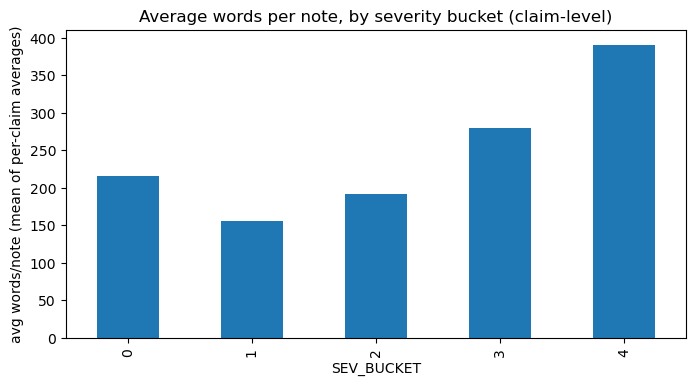

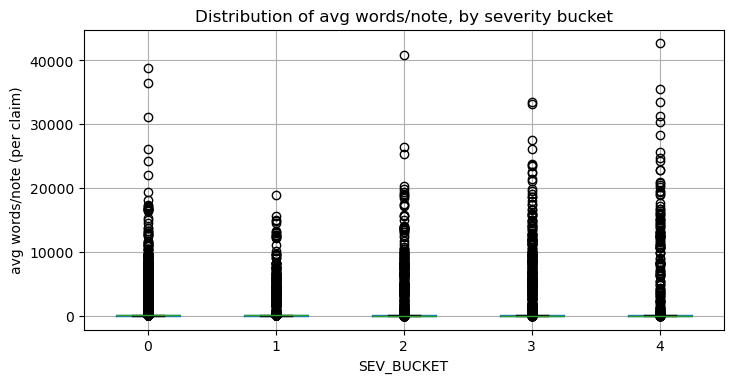

In [26]:
claim_sev_bucket = cov_full.groupby('CLM_NUM')['SEV_BUCKET'].max().rename('SEV_BUCKET')
claim_sev_bucket.index = claim_sev_bucket.index.astype(str)

claim_note_len = notes_meta.groupby('CLAIM_NUM')[['N_WORDS', 'N_CHARS']].mean()
claim_note_len.columns = ['AVG_WORDS_PER_NOTE', 'AVG_CHARS_PER_NOTE']
claim_note_len.index = claim_note_len.index.astype(str)

claim_level = claim_note_len.merge(claim_sev_bucket, left_index=True, right_index=True, how='inner')

summary = claim_level.groupby('SEV_BUCKET')[['AVG_WORDS_PER_NOTE', 'AVG_CHARS_PER_NOTE']].agg(['mean', 'median'])
summary['N_CLAIMS'] = claim_level.groupby('SEV_BUCKET').size()
print(summary)

claim_level.groupby('SEV_BUCKET')['AVG_WORDS_PER_NOTE'].mean().plot(kind='bar', figsize=(8, 4))
plt.title('Average words per note, by severity bucket (claim-level)')
plt.xlabel('SEV_BUCKET')
plt.ylabel('avg words/note (mean of per-claim averages)')
plt.show()

claim_level.boxplot(column='AVG_WORDS_PER_NOTE', by='SEV_BUCKET', figsize=(8, 4))
plt.title('Distribution of avg words/note, by severity bucket')
plt.suptitle('')
plt.xlabel('SEV_BUCKET')
plt.ylabel('avg words/note (per claim)')
plt.show()

---
## Label distribution by ORG_GROUP_NAME (Direct vs. Independent)

Attorney / Litigation rate by ORG_GROUP_NAME:
                ATTNY_FLG  LITIG_FLG  N_COVERAGES
ORG_GROUP_NAME                                   
Direct           0.406794   0.098151        76036
Independent      0.462106   0.052988        93286


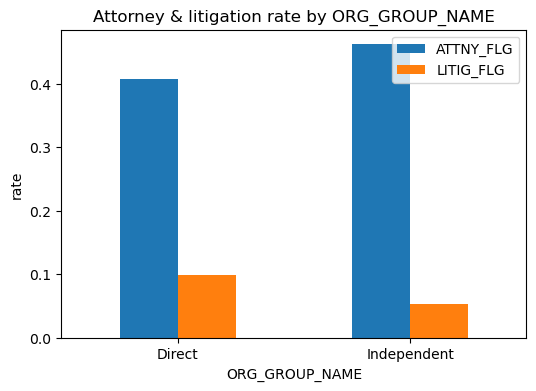

In [27]:
org_rates = cov_full.groupby('ORG_GROUP_NAME')[['ATTNY_FLG', 'LITIG_FLG']].mean()
org_rates['N_COVERAGES'] = cov_full.groupby('ORG_GROUP_NAME').size()
print('Attorney / Litigation rate by ORG_GROUP_NAME:')
print(org_rates)

org_rates[['ATTNY_FLG', 'LITIG_FLG']].plot(kind='bar', figsize=(6, 4))
plt.title('Attorney & litigation rate by ORG_GROUP_NAME')
plt.xlabel('ORG_GROUP_NAME')
plt.ylabel('rate')
plt.xticks(rotation=0)
plt.show()

### Severity bucket mix by ORG_GROUP_NAME

SEV_BUCKET          0      1      2      3      4
ORG_GROUP_NAME                                   
Direct          0.657  0.135  0.119  0.064  0.025
Independent     0.560  0.180  0.128  0.096  0.036


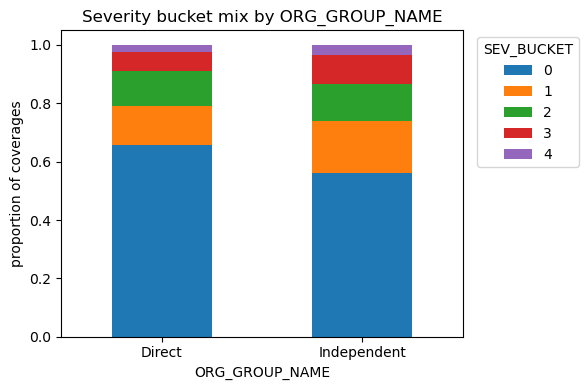

In [28]:
sev_by_org = pd.crosstab(cov_full['ORG_GROUP_NAME'], cov_full['SEV_BUCKET'], normalize='index')
print(sev_by_org.round(3))

sev_by_org.plot(kind='bar', stacked=True, figsize=(6, 4))
plt.title('Severity bucket mix by ORG_GROUP_NAME')
plt.xlabel('ORG_GROUP_NAME')
plt.ylabel('proportion of coverages')
plt.xticks(rotation=0)
plt.legend(title='SEV_BUCKET', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
## Label distribution by state

Using `LOSS_STATE` (where the accident happened — the state whose negligence/statute-of-limitations
law actually governs the claim) rather than `POL_STATE` (where the policy was written); the two mostly
agree but occasionally differ. Smaller states have very few coverages, so their rates are noisy — `N`
is shown alongside every rate for that reason.

Attorney / Litigation rate by LOSS_STATE (sorted by volume):
            ATTNY_FLG  LITIG_FLG  N_COVERAGES
LOSS_STATE                                   
NJ           0.396290   0.116133        81458
MA           0.483330   0.009696        49610
NY           0.494471   0.082780        15825
PA           0.365190   0.059701         8308
CT           0.567847   0.075877         6102
NH           0.279541   0.010128         1481
FL           0.520791   0.032720         1467
RI           0.656197   0.011885         1178
MD           0.413629   0.022187          631
DE           0.335366   0.046748          492
VA           0.331412   0.037464          347
CA           0.482759   0.018809          319
NC           0.350820   0.029508          305
SC           0.384615   0.028340          247
GA           0.539419   0.033195          241
ME           0.213018   0.011834          169
OH           0.433824   0.044118          136
TX           0.552632   0.043860          114
VT           0.1855

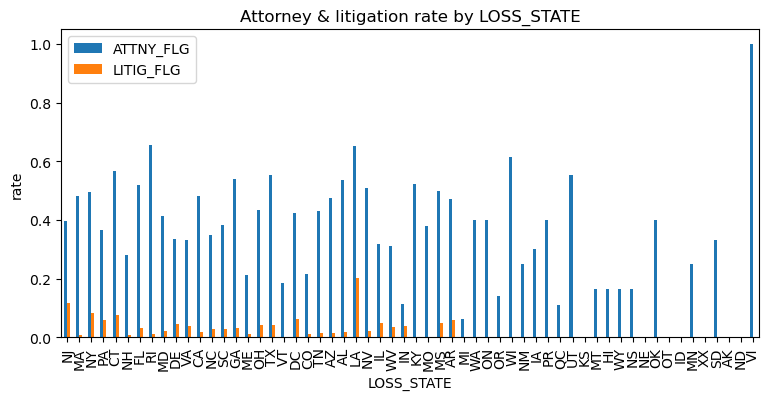

In [29]:
state_rates = cov_full.groupby('LOSS_STATE')[['ATTNY_FLG', 'LITIG_FLG']].mean()
state_rates['N_COVERAGES'] = cov_full.groupby('LOSS_STATE').size()
state_rates = state_rates.sort_values('N_COVERAGES', ascending=False)
print('Attorney / Litigation rate by LOSS_STATE (sorted by volume):')
print(state_rates)

state_rates[['ATTNY_FLG', 'LITIG_FLG']].plot(kind='bar', figsize=(9, 4))
plt.title('Attorney & litigation rate by LOSS_STATE')
plt.xlabel('LOSS_STATE')
plt.ylabel('rate')
plt.show()

### Severity bucket mix by state (top 6 states by volume)

SEV_BUCKET      0      1      2      3      4
LOSS_STATE                                   
NJ          0.637  0.150  0.106  0.070  0.037
MA          0.520  0.218  0.165  0.082  0.016
NY          0.707  0.073  0.078  0.108  0.034
PA          0.672  0.117  0.127  0.058  0.025
CT          0.488  0.129  0.140  0.187  0.056
NH          0.619  0.148  0.093  0.097  0.044


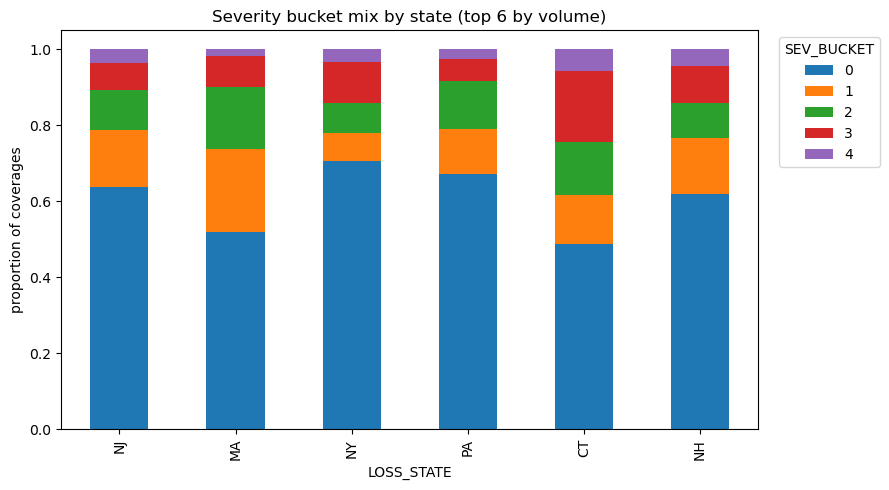

In [30]:
top_states = state_rates.head(6).index

sev_by_state = pd.crosstab(cov_full['LOSS_STATE'], cov_full['SEV_BUCKET'], normalize='index').loc[top_states]
print(sev_by_state.round(3))

sev_by_state.plot(kind='bar', stacked=True, figsize=(9, 5))
plt.title('Severity bucket mix by state (top 6 by volume)')
plt.xlabel('LOSS_STATE')
plt.ylabel('proportion of coverages')
plt.legend(title='SEV_BUCKET', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
## Days-since-claim-open distributions for Attorney, Litigation, and Severity

For every `CLM_CVG_PK`, how many days after `CLM_OPEN_DT` did the event happen:
- **Attorney** — `ATTNY_DT - CLM_OPEN_DT`, only coverages where `ATTNY_FLG == 1`
- **Litigation** — `LITIG_DT - CLM_OPEN_DT`, only coverages where `LITIG_FLG == 1`
- **Severity** — no event date exists, so the analog is `LAST_CLOSE_DT - CLM_OPEN_DT` (days until the
  coverage closes, i.e. until the ultimate `SEV_BUCKET` is actually known), for every closed coverage

Attorney: days from CLM_OPEN_DT to ATTNY_DT - describe():
count    74039.000000
mean       105.548008
std        207.338355
min      -1843.000000
25%         10.000000
50%         31.000000
75%         88.000000
max       2892.000000
dtype: float64

quantiles:
0.00   -1843.0
0.01      -3.0
0.05       0.0
0.10       0.0
0.25      10.0
0.50      31.0
0.75      88.0
0.90     300.0
0.95     558.0
0.99     992.0
1.00    2892.0
dtype: float64


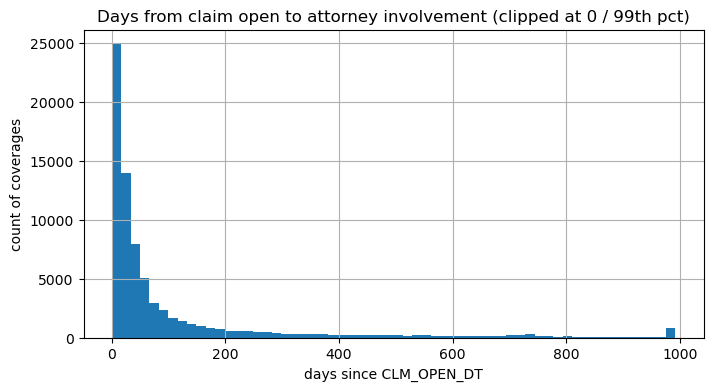

In [34]:
atty_days = (cov_full.loc[cov_full.ATTNY_FLG == 1, 'ATTNY_DT'] - cov_full.loc[cov_full.ATTNY_FLG == 1, 'CLM_OPEN_DT']).dt.days

print('Attorney: days from CLM_OPEN_DT to ATTNY_DT - describe():')
print(atty_days.describe())
print('\nquantiles:')
print(atty_days.quantile(QUANTILES))

atty_days.clip(lower=0, upper=atty_days.quantile(0.99)).hist(bins=60, figsize=(8, 4), color='tab:blue')
plt.title('Days from claim open to attorney involvement (clipped at 0 / 99th pct)')
plt.xlabel('days since CLM_OPEN_DT')
plt.ylabel('count of coverages')
plt.show()

Litigation: days from CLM_OPEN_DT to LITIG_DT - describe():
count    12399.000000
mean       620.857972
std        331.827900
min      -6799.000000
25%        408.000000
50%        666.000000
75%        759.000000
max       2917.000000
dtype: float64

quantiles:
0.00   -6799.00
0.01       3.00
0.05     126.00
0.10     223.00
0.25     408.00
0.50     666.00
0.75     759.00
0.90     935.00
0.95    1123.00
0.99    1700.04
1.00    2917.00
dtype: float64


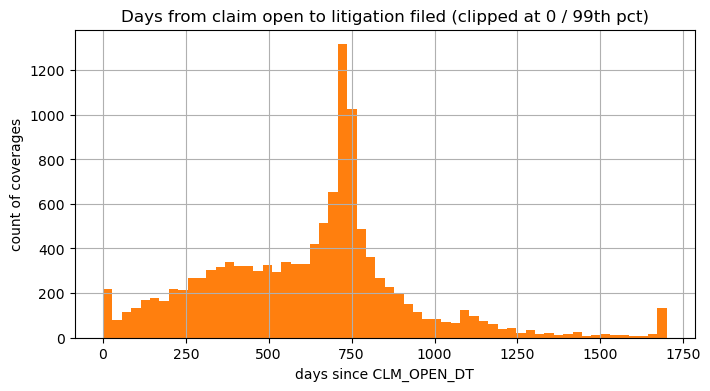

In [35]:
litig_days = (cov_full.loc[cov_full.LITIG_FLG == 1, 'LITIG_DT'] - cov_full.loc[cov_full.LITIG_FLG == 1, 'CLM_OPEN_DT']).dt.days

print('Litigation: days from CLM_OPEN_DT to LITIG_DT - describe():')
print(litig_days.describe())
print('\nquantiles:')
print(litig_days.quantile(QUANTILES))

litig_days.clip(lower=0, upper=litig_days.quantile(0.99)).hist(bins=60, figsize=(8, 4), color='tab:orange')
plt.title('Days from claim open to litigation filed (clipped at 0 / 99th pct)')
plt.xlabel('days since CLM_OPEN_DT')
plt.ylabel('count of coverages')
plt.show()

Severity: days from CLM_OPEN_DT to LAST_CLOSE_DT (when SEV_BUCKET becomes known) - describe():
count    164324.000000
mean        572.115388
std         517.959948
min           0.000000
25%         180.000000
50%         409.000000
75%         839.000000
max        3938.000000
dtype: float64

quantiles:
0.00       0.0
0.01       4.0
0.05      36.0
0.10      75.0
0.25     180.0
0.50     409.0
0.75     839.0
0.90    1272.0
0.95    1565.0
0.99    2277.0
1.00    3938.0
dtype: float64


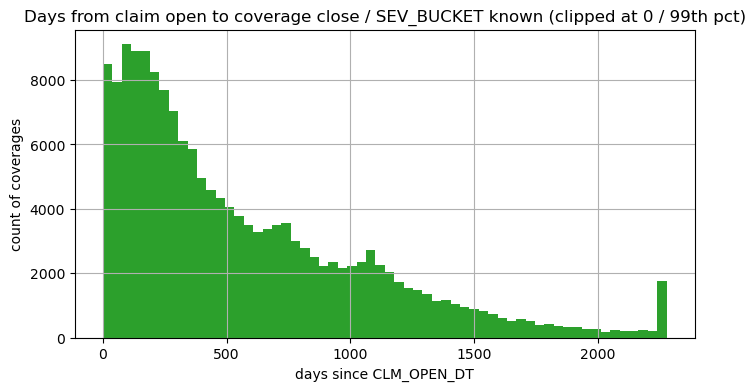

In [36]:
sev_days = (cov_full.loc[cov_full.LAST_CLOSE_DT.notna(), 'LAST_CLOSE_DT'] - cov_full.loc[cov_full.LAST_CLOSE_DT.notna(), 'CLM_OPEN_DT']).dt.days

print('Severity: days from CLM_OPEN_DT to LAST_CLOSE_DT (when SEV_BUCKET becomes known) - describe():')
print(sev_days.describe())
print('\nquantiles:')
print(sev_days.quantile(QUANTILES))

sev_days.clip(lower=0, upper=sev_days.quantile(0.99)).hist(bins=60, figsize=(8, 4), color='tab:green')
plt.title('Days from claim open to coverage close / SEV_BUCKET known (clipped at 0 / 99th pct)')
plt.xlabel('days since CLM_OPEN_DT')
plt.ylabel('count of coverages')
plt.show()